In [1]:
!pip uninstall -y massi
!pip cache purge

Files removed: 6 (1.2 MB)


In [2]:
!cd .. && pip install -v . --group=dev --group=observability --group=sandbox

Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
Processing /home/jovyan/work
  Running command installing build dependencies
  Using pip 25.3 from /opt/conda/lib/python3.13/site-packages/pip (python 3.13)
    Obtaining dependency information for setuptools>=40.8.0 from https://files.pythonhosted.org/packages/9d/76/f789f7a86709c6b087c5a2f52f911838cad707cc613162401badc665acfe/setuptools-82.0.1-py3-none-any.whl.metadata
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0.0/1.0 MB ? eta -:--:--
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.8 MB/s  0:00:00
  Installing build dependencies ... done
  Running command Getting requirements to build wheel
  running egg_info
  writing massi.egg-info/PKG-INFO
  writing dependency_links to massi.egg-info/dependency_links.txt
  writing requirements to massi.egg-info/requires.txt
  writing top-level names to massi.egg-info/top_level.txt
  reading manifest file 'massi.egg-info/SOURCES.txt'
  writing manifest file

In [3]:
# Setup observability
USE_OBSERVABILITY = True

if USE_OBSERVABILITY:
    import os
    from lmnr import Laminar
    
    Laminar.initialize(
        project_api_key=os.environ["LMNR_PROJECT_API_KEY"],
        base_url=f"http://{os.environ["HOST_MACHINE_URL_CORE"]}",
        http_port=int(os.environ["LMNR_PROJECT_HTTP_PORT"]),
        grpc_port=int(os.environ["LMNR_PROJECT_GRPC_PORT"]),
        metadata={"case": "demo-eml-x-author"},
    )
    print("Observability is ready")

/opt/conda/lib/python3.13/site-packages/langgraph/cache/base/__init__.py:8: LangChainPendingDeprecationWarning: The default value of `allowed_objects` will change in a future version. Pass an explicit value (e.g., allowed_objects='messages' or allowed_objects='core') to suppress this warning.
  from langgraph.checkpoint.serde.jsonplus import JsonPlusSerializer


Observability is ready


In [4]:
import lmnr
lmnr.version

<module 'lmnr.version' from '/opt/conda/lib/python3.13/site-packages/lmnr/version.py'>

In [5]:
from massi.agents.interfaces import Config

In [6]:
from massi.agents.interfaces import create_ollama_llm

base_config = Config(**{"model_url": "http://host.docker.internal:11434", "model_name": "granite4:3b"})
base_llm_client=create_ollama_llm(base_config)

In [7]:
from massi.agents.interfaces import create_openai_llm
openai_config = Config(**{"api_key": os.environ["OPENAI_API_TOKEN"], "model_name": "gpt-5.4-mini"})
openai_llm_client = create_openai_llm(openai_config)

In [8]:
from massi.agents.team.telecom.author_proxy import create_openai_embeddings
open_ai_embeddings_config = Config(model_name="text-embedding-3-small", api_key=os.environ["OPENAI_API_TOKEN"])
open_ai_embeddings = create_openai_embeddings(open_ai_embeddings_config)

In [9]:
USE_OPEN_AI = True

print(">>> Using OpenAI") if USE_OPEN_AI else print(">>> Using Ollama")
main_llm = openai_llm_client if USE_OPEN_AI else base_llm_client
main_embeddings = open_ai_embeddings if USE_OPEN_AI else None

>>> Using OpenAI


# Starting the `EML`-x-`Author` massi

In [10]:
assert main_embeddings, "Can not proceed with the Author-Focused execution without an embedding model"

In [11]:
from pathlib import Path
import massi.agents.team.telecom.author_proxy as maupy

rag_author_proxy = maupy.RagAuthorProxyQueryClient.build_client(
    [Path('papers/budburst-paper.pdf')],
    {"embedder": main_embeddings},
    {"generator": main_llm},
)

In [12]:
import massi.agents.workflow as mw 

In [13]:
import massi.agents.team.architect as march
import massi.agents.team.planner as mplan

architect_map = {
    "darwin_core": march.DarwinCoreArchitect(main_llm),
    "eml": march.EMLArchitect(main_llm),
}
planner_map = {
    "darwin_core": mplan.DarwinCorePlanner(main_llm),
    "eml": mplan.EMLPlanner(main_llm),
}

In [14]:
import massi.agents.team.instructors as minrs
import massi.agents.team.operators as mopers

derivation_map = {
    'data-focus': mopers.DataGapDervationOperator(main_llm, recursion_limit=25, turn_limit=5),
    'author-focus': mopers.AuthorGapDervationOperator(main_llm, rag_author_proxy, recursion_limit=25, turn_limit=5),
}

derivation_instructors_map = {
    'data-focus': minrs.DataGapDerivationInstructor(main_llm),
    'author-focus': minrs.AuthorGapDerivationInstructor(main_llm),
}

In [15]:
dependency_base: mw.Dependencies = dict(
    execution_mode='author-focus',

    architect_map=architect_map,
    planner_map=planner_map,
    gap_derivation_instructor_map=derivation_instructors_map,
    derivation_map=derivation_map,
)

In [16]:
resolution_dependencies = mw.Dependencies(**dependency_base)

In [17]:
goal_workflow = mw._build_goal_resolution_graph(resolution_dependencies)

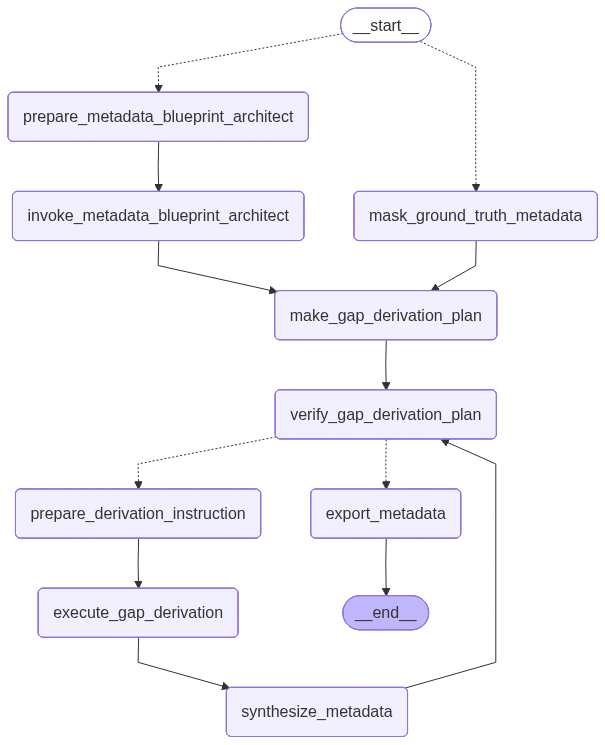

In [18]:
goal_workflow.graph

In [19]:
core_dependencies = mw.Dependencies(**dependency_base, metadata_resolution_subgraph=goal_workflow)

In [20]:
core_workflow = mw.build_graph(core_dependencies)

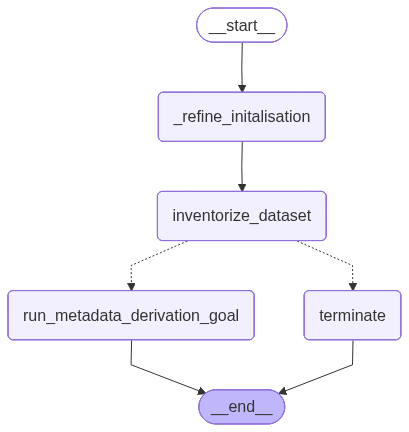

In [21]:
core_workflow.graph

## Inference

In [22]:
import massi.agents.tools as mt
import massi.agents.team._dto as mdto

In [23]:
dwc_data_file_metadata_goal: mw.MetadataGoal = {
    "level": mdto.MetadataLevel.ITEM,
    "scopes": [mdto.MetadataScope.DESCRIPTIVE, mdto.MetadataScope.TECHNICAL, mdto.MetadataScope.USE],
    "target_filename": "meta.xml",
    "schema_source": "https://dwc.tdwg.org/text/tdwg_dwc_text.xsd",
    "description": (
        "This metadata file describes the archive and data file structure."
        "A descriptor metafile describes how the files in your archive are organized."
        "It describes the files in the archive and maps each data column to a corresponding standard Darwin Core or Extension term."
        "The metafile is a relatively simple XML file format."
    ),
    "metadata_goal_key": "darwin_core",
}

In [24]:
print(mt.get_xmlschema_validator(dwc_data_file_metadata_goal["schema_source"]).to_string())

/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/terms/' from ['http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/2008/02/11/dcterms.xsd': Forbidden.
  return self.schema_class(
/opt/conda/lib/python3.13/site-packages/xmlschema/loaders.py:312: XMLSchemaImportWarning: Import of namespace 'http://purl.org/dc/elements/1.1/' from ['http://dublincore.org/schemas/xmls/qdc/dc.xsd'] failed: can't access to resource 'http://dublincore.org/schemas/xmls/qdc/dc.xsd': Forbidden.
  return self.schema_class(


<xs:schema xmlns:xs="http://www.w3.org/2001/XMLSchema" version="0.1" targetNamespace="http://rs.tdwg.org/dwc/text/" attributeFormDefault="unqualified" elementFormDefault="qualified">
    <xs:import namespace="http://rs.tdwg.org/dwc/terms/" schemaLocation="https://raw.githubusercontent.com/tdwg/dwc/master/docs/xml/tdwg_dwcterms.xsd" />
    <xs:import namespace="http://www.w3.org/XML/1998/namespace" schemaLocation="http://rs.gbif.org/schema/xml.xsd">
        <xs:annotation>
            <xs:documentation>
                Get access to the xml: attribute groups for xml:lang
            </xs:documentation>
        </xs:annotation>
    </xs:import>
    
    
    <xs:element name="archive">
        <xs:complexType>
            <xs:sequence>
                <xs:element name="core" type="arch:coreFileType" maxOccurs="1" minOccurs="1" />
                <xs:element name="extension" type="arch:extensionFileType" maxOccurs="unbounded" minOccurs="0" />
            </xs:sequence>
            <xs:att

In [25]:
dwc_eml_metadata_goal: mw.MetadataGoal = {
    "level": mdto.MetadataLevel.COLLECTION,
    "scopes": [
        mdto.MetadataScope.DESCRIPTIVE,
        mdto.MetadataScope.ADMINISTRATIVE,
        mdto.MetadataScope.PRESERVATION,
        mdto.MetadataScope.USE,
    ],
    "target_filename": "eml.xml",
    "schema_source": "https://eml.ecoinformatics.org/eml-2.2.0/eml.xsd",
    "description": (
        "This metadata file contains the dataset's aggregate metadata."
        "This is a resource metadata document that provides information about the dataset itself such as a description (abstract) of the dataset, the agents responsible for authorship, publication and documentation, bibliographic and citation information, collection methods and much more."
        "It is based on the Ecological Metadata Language."
    ),
    "metadata_goal_key": "eml",
}

In [26]:
print(mt.get_xmlschema_validator(dwc_eml_metadata_goal["schema_source"]).to_string())

<xs:schema xmlns:doc="https://eml.ecoinformatics.org/documentation-2.2.0" xmlns:xs="http://www.w3.org/2001/XMLSchema" targetNamespace="https://eml.ecoinformatics.org/eml-2.2.0">
    <xs:import namespace="https://eml.ecoinformatics.org/documentation-2.2.0" schemaLocation="eml-documentation.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/dataset-2.2.0" schemaLocation="eml-dataset.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/literature-2.2.0" schemaLocation="eml-literature.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/software-2.2.0" schemaLocation="eml-software.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/protocol-2.2.0" schemaLocation="eml-protocol.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/resource-2.2.0" schemaLocation="eml-resource.xsd" />
    <xs:import namespace="https://eml.ecoinformatics.org/access-2.2.0" schemaLocation="eml-access.xsd" />
    <xs:import namespace="https://eml.ecoinf

## Mask available metadata

In [27]:
!rm -rf dwc_data/masked-doi-10.34894-72gq4c/.*
!rm -rf dwc_data/masked-doi-10.34894-72gq4c/meta.xml
!rm -rf dwc_data/masked-doi-10.34894-72gq4c/eml.xml

## Run the inference

In [28]:
import random

In [29]:
thread_config = {"configurable": {"thread_id": str(random.randint(1, 100))}}

base_state: mw.MassiCoreState = {
    "settings": {
        "runtime_config": {
            "working_directory": "./dwc_data/masked-doi-10.34894-72gq4c", 
            "output_directory": "./dwc_data/masked-doi-10.34894-72gq4c"
        },
        "execution_mode": "author-focus"
    },
    "goals": [dwc_eml_metadata_goal]
}

In [30]:
outcome = core_workflow.graph.invoke(base_state, thread_config)

In [31]:
from pprint import pprint

In [32]:
print(outcome["resolutions"][0]["architect_xml_blueprint"]["content"])

<?xml version="1.0" encoding="UTF-8"?>
<eml:eml packageId="{{GAP_000:STRING:PACKAGE_ID}}" system="knb" xmlns:eml="https://eml.ecoinformatics.org/eml-2.2.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xml:lang="en">
  <dataset>
    <title>{{GAP_001:STRING:DATASET_TITLE}}</title>

    <creator>
      <individualName>
        <surName>{{GAP_002:STRING:PI_SURNAME}}</surName>
      </individualName>
      <userId directory="https://orcid.org">{{GAP_003:URI:ORCID}}</userId>
    </creator>

    <abstract>
      <para>{{GAP_013:STRING:DATASET_ABSTRACT_AND_RESEARCH_CONTEXT}}</para>
    </abstract>

    <methods>
      <methodStep>
        <description>
          <para>{{GAP_004:STRING:SAMPLING_PROTOCOL_NARRATIVE}}</para>
        </description>
        <instrumentation>{{GAP_005:STRING:SENSOR_OR_EQUIPMENT_SPECS}}</instrumentation>
      </methodStep>
      <qualityControl>
        <description>
          <para>{{GAP_006:STRING:QA_QC_PROCEDURES}}</para>
        </description>
      </qu

In [33]:
pprint(outcome["resolutions"][0]["gap_derivation_plan"])

{'gaps': [{'gap_derivation_request': 'The packageId is not explicitly stated '
                                     'in the provided context. Derive a '
                                     'globally unique identifier for the EML '
                                     'package, preferably using the dataset '
                                     'DOI pattern if available from repository '
                                     'context; otherwise generate a UUID- or '
                                     'DOI-like persistent identifier and '
                                     'verify it is globally unique and '
                                     'resolvable if required by the target '
                                     'system.',
           'gap_description': 'EML package identifier for the metadata '
                              'document.',
           'gap_id': 'GAP_000',
           'gap_replacement_pattern': '{{GAP_000:STRING:PACKAGE_ID}}',
           'gap_scope_files': ['/home/

In [34]:
print(outcome["resolutions"][0]["working_copy_xml_blueprint"]["content"])

<?xml version="1.0" encoding="UTF-8"?>
<eml:eml packageId="{{GAP_000:STRING-response[\"success\"]=False-response[\"status\"]='completed':{'The author did not provide a definitive dataset package identifier for the EML `packageId` field. No DOI, repository accession, handle, internal identifier, or UUID-style `packageId` was supplied, so the identifier remains unresolved and would need to be chosen or approved later.'}}}" system="knb" xmlns:eml="https://eml.ecoinformatics.org/eml-2.2.0" xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance" xml:lang="en">
  <dataset>
    <title>{{GAP_001:STRING-response[\"success\"]=False-response[\"status\"]='completed':{'The interview reached its turn limit without obtaining an official dataset title. The author/context did not provide a definitive title from the DOI landing page, repository record, README, or manuscript, so no valid string could be finalized.'}}}</title>

    <creator>
      <individualName>
        <surName>{{GAP_002:STRING-response[